In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
df=pd.read_csv('/content/twitter_validation.csv',header=None,encoding="ISO-8859-1")
df

,0,1,2,3
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
...,...,...,...,...
995,4891,GrandTheftAuto(GTA),Irrelevant,â­ï¸ Toronto is the arts and culture capital...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
#giving column names
df.columns=["Id","Media","Target","Text"]
df

,Id,Media,Target,Text
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
...,...,...,...,...
995,4891,GrandTheftAuto(GTA),Irrelevant,â­ï¸ Toronto is the arts and culture capital...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
#DATA UNDERSTANDING

#first 3 rows
print(df.head())

     Id      Media      Target  \
0  3364   Facebook  Irrelevant   
1   352     Amazon     Neutral   
2  8312  Microsoft    Negative   
3  4371      CS-GO    Negative   
4  4433     Google     Neutral   

                                                Text  
0  I mentioned on Facebook that I was struggling ...  
1  BBC News - Amazon boss Jeff Bezos rejects clai...  
2  @Microsoft Why do I pay for WORD when it funct...  
3  CSGO matchmaking is so full of closet hacking,...  
4  Now the President is slapping Americans in the...  


In [ ]:
#last 3 rows
print(df.tail(3))

       Id            Media    Target  \
997  2652      Borderlands  Positive   
998  8069        Microsoft  Positive   
999  6960  johnson&johnson   Neutral   

                                                  Text  
997  Today sucked so itâs time to drink wine n pl...  
998  Bought a fraction of Microsoft today. Small wins.  
999  Johnson & Johnson to stop selling talc baby po...  


In [ ]:
#number of rows and columns
print(df.shape)
#dimension'
print(df.ndim)

(1000, 4)
2


In [ ]:
#statistical summary
print(df.describe(include=object))

                         Media   Target  Text
count                     1000     1000  1000
unique                      32        4   999
top     RedDeadRedemption(RDR)  Neutral   Wow
freq                        40      285     2


In [ ]:
#informations
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Id      1000 non-null   int64 
 1   Media   1000 non-null   object
 2   Target  1000 non-null   object
 3   Text    1000 non-null   object
dtypes: int64(1), object(3)
memory usage: 31.4+ KB
None


In [ ]:
#number of unique values
print(df.nunique())

Id        1000
Media       32
Target       4
Text       999
dtype: int64


In [ ]:
#column names
print(df.columns)

Index(['Id', 'Media', 'Target', 'Text'], dtype='object')


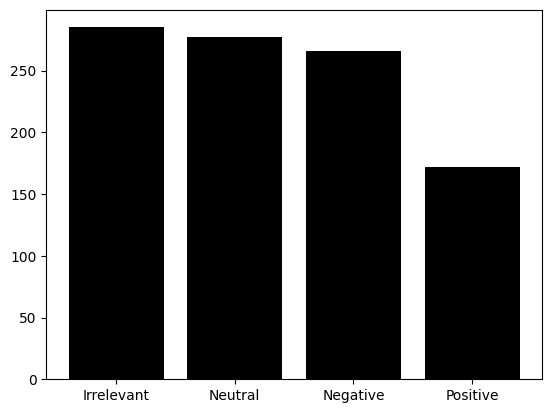

In [ ]:
#DATA CLEANING AND VISUALIZATION

x=df['Target'].unique()
y=df['Target'].value_counts()
plt.bar(x,y,color='black')
plt.show()

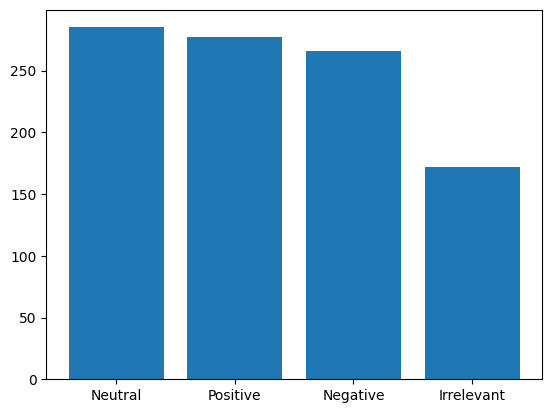

In [ ]:
#or another method
df1=df['Target'].value_counts()
plt.bar(df1.index,df1.values)
plt.show()

In [ ]:
#removing irrelevent values from target column
df.drop(df[df['Target'] == 'Irrelevant'].index, inplace=True)
print(df['Target'].value_counts())
df.reset_index(drop=True,inplace=True)   #to correct the index value after removing the 'irrelevant' rows
df

Target
Neutral     285
Positive    277
Negative    266
Name: count, dtype: int64


,Id,Media,Target,Text
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,4433,Google,Neutral,Now the President is slapping Americans in the...
4,6273,FIFA,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...,...,...
823,314,Amazon,Negative,Please explain how this is possible! How can t...
824,9701,PlayStation5(PS5),Positive,Good on Sony. As much as I want to see the new...
825,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
826,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
#removing id and media as it is not needed for analysing review
df=df.drop(['Id','Media'],axis=1)
df

,Target,Text
0,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,Negative,@Microsoft Why do I pay for WORD when it funct...
2,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,Neutral,Now the President is slapping Americans in the...
4,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...
823,Negative,Please explain how this is possible! How can t...
824,Positive,Good on Sony. As much as I want to see the new...
825,Positive,Today sucked so itâs time to drink wine n pl...
826,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
#target column
df['Target']=df['Target'].map({'Negative':-1, 'Neutral':0,'Positive':1})
df

,Target,Text
0,0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,-1,@Microsoft Why do I pay for WORD when it funct...
2,-1,"CSGO matchmaking is so full of closet hacking,..."
3,0,Now the President is slapping Americans in the...
4,-1,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...
823,-1,Please explain how this is possible! How can t...
824,1,Good on Sony. As much as I want to see the new...
825,1,Today sucked so itâs time to drink wine n pl...
826,1,Bought a fraction of Microsoft today. Small wins.


In [ ]:
df['Target'].unique()

array([ 0, -1,  1])

In [ ]:
#NLP PREPROCESSING STEPS ON TEXT COLUMNS

In [ ]:
#defining text column to a variable
tweets=df['Text']
tweets

,Text
0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,@Microsoft Why do I pay for WORD when it funct...
2,"CSGO matchmaking is so full of closet hacking,..."
3,Now the President is slapping Americans in the...
4,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...
823,Please explain how this is possible! How can t...
824,Good on Sony. As much as I want to see the new...
825,Today sucked so itâs time to drink wine n pl...
826,Bought a fraction of Microsoft today. Small wins.


In [ ]:
#tokenization
nltk.download('punkt_tab')
from nltk.tokenize import TweetTokenizer
tk=TweetTokenizer()
tweets=tweets.apply(lambda x:tk.tokenize(x)).apply(lambda x:" ".join(x))
tweets

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,Text
0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,@Microsoft Why do I pay for WORD when it funct...
2,CSGO matchmaking is so full of closet hacking ...
3,Now the President is slapping Americans in the...
4,Hi @EAHelp Iâ   ve had Madeleine McCann in m...
...,...
823,Please explain how this is possible ! How can ...
824,Good on Sony . As much as I want to see the ne...
825,Today sucked so itâ   s time to drink wine n...
826,Bought a fraction of Microsoft today . Small w...


In [ ]:
#REMOVING SPECIAL CHARA
tweets=tweets.replace('[^a-zA-Z0-9]',' ',regex=True)
tweets

,Text
0,BBC News Amazon boss Jeff Bezos rejects clai...
1,Microsoft Why do I pay for WORD when it funct...
2,CSGO matchmaking is so full of closet hacking ...
3,Now the President is slapping Americans in the...
4,Hi EAHelp I ve had Madeleine McCann in m...
...,...
823,Please explain how this is possible How can ...
824,Good on Sony As much as I want to see the ne...
825,Today sucked so it s time to drink wine n...
826,Bought a fraction of Microsoft today Small w...


In [ ]:
#tokenization and removing of words less than 3 letters
tweets=tweets.apply(lambda x:" ".join([i for i in tk.tokenize(x) if len(i) >= 3]))
tweets

,Text
0,BBC News Amazon boss Jeff Bezos rejects claims...
1,Microsoft Why pay for WORD when functions poor...
2,CSGO matchmaking full closet hacking truly awf...
3,Now the President slapping Americans the face ...
4,EAHelp had Madeleine McCann cellar for the pas...
...,...
823,Please explain how this possible How can they ...
824,Good Sony much want see the new PS5 what going...
825,Today sucked time drink wine play borderlands ...
826,Bought fraction Microsoft today Small wins


In [ ]:
#stemming using snowball  stemmer and stop words removal
nltk.download('stopwords')
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
stop=stopwords.words('english')
st=SnowballStemmer('english')
tweets = tweets.apply(lambda x: " ".join([st.stem(i.lower()) for i in tk.tokenize(x) if i.lower() not in stop]))
tweets

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,Text
0,bbc news amazon boss jeff bezo reject claim co...
1,microsoft pay word function poor samsungus chr...
2,csgo matchmak full closet hack truli aw game
3,presid slap american face realli commit unlaw ...
4,eahelp madelein mccann cellar past year littl ...
...,...
823,pleas explain possibl let compani overcharg sc...
824,good soni much want see new ps5 go right much ...
825,today suck time drink wine play borderland sun...
826,bought fraction microsoft today small win


In [ ]:
#VECTORIZATION-TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer
vec= TfidfVectorizer()
data=vec.fit_transform(tweets)
data


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10359 stored elements and shape (828, 3756)>

In [ ]:
#input output separation
x=data
y=df['Target']
x

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10359 stored elements and shape (828, 3756)>

In [ ]:
#TRAIN TEST SPLITTING
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.30,random_state=41)
print(xtrain.shape)
print(ytrain.shape)
print(xtest.shape)

(579, 3756)
(579,)
(249, 3756)


In [ ]:
#DATA BALANCING
print(ytrain.value_counts())
from imblearn.over_sampling import SMOTE
sm=SMOTE()
xtrain1,ytrain1=sm.fit_resample(xtrain,ytrain)
print(ytrain1.value_counts())


Target
 0    204
 1    189
-1    186
Name: count, dtype: int64
Target
 0    204
 1    204
-1    204
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import GridSearchCV
#HYPERPARAMETER TUNING OF KNN
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier()
knn_param={'n_neighbors':[5,7,9,11],'weights':['distance','random'],'metric':['euclidean','manhattan']}
knn_grid=GridSearchCV(knn_model,knn_param,cv=3,scoring='accuracy')
knn_grid.fit(xtrain1,ytrain1)
#best performing parameters
knn_grid.best_params_

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
24 fits failed out of a total of 48.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
24 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_par

{'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'distance'}

In [ ]:
#KNN MODEL BUILDING
knn=KNeighborsClassifier(metric= 'euclidean', n_neighbors= 9, weights= 'distance')
#training
knn.fit(xtrain1,ytrain1)
#testing
knn_ypred=knn.predict(xtest)
knn_ypred

array([-1, -1, -1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1

In [ ]:
#HYPERPARAMETER TUNING OF NB
from sklearn.naive_bayes import BernoulliNB
nb_model=BernoulliNB()
nb_param={'alpha':[0.1,0.5,1.0,5.0,10.0],'binarize':[0.0,0.5,1.0],'fit_prior':[True,False]}
nb_grid=GridSearchCV(nb_model,nb_param,cv=3,scoring='accuracy')
nb_grid.fit(xtrain1,ytrain1)
#best performing parameters
nb_grid.best_params_

{'alpha': 1.0, 'binarize': 0.0, 'fit_prior': True}

In [ ]:
#NB MODEL BUILDING
nb=BernoulliNB(alpha= 0.1, binarize= 0.0, fit_prior= True)
nb.fit(xtrain1,ytrain1)
nb_ypred=nb.predict(xtest)
nb_ypred

array([-1, -1,  1,  1,  1,  0,  0, -1, -1, -1,  0,  0,  1, -1,  1,  1,  1,
        0,  1, -1,  1,  1,  0,  1,  1, -1,  1, -1, -1,  0, -1,  1, -1, -1,
        1, -1,  1,  0,  1,  1,  1,  1,  1,  0,  1,  1,  0, -1,  0, -1, -1,
        1,  0, -1,  1,  0,  1,  1, -1, -1,  1, -1, -1,  1, -1,  1, -1,  1,
       -1,  1,  0,  1, -1,  1,  0, -1,  0,  1, -1, -1, -1,  1, -1,  0,  0,
       -1,  1,  1,  0,  1,  1,  0,  0,  0,  1,  1,  1,  1,  0,  1,  1,  1,
       -1,  1,  1, -1, -1,  0,  1,  1,  0, -1, -1,  1, -1, -1,  1, -1, -1,
       -1, -1,  1, -1, -1,  1, -1,  0,  1, -1,  1,  0,  0, -1,  0,  0, -1,
        1, -1, -1, -1, -1,  1,  0,  1, -1,  1, -1,  1,  1,  0,  1,  0,  1,
       -1,  1, -1,  1,  1,  1, -1,  0, -1, -1,  1,  0, -1,  1,  1, -1, -1,
        0,  1, -1,  1,  0,  1, -1,  0, -1, -1,  1,  0, -1, -1, -1, -1,  1,
        0,  1,  1, -1, -1,  0,  1,  1, -1, -1,  0, -1,  1, -1,  1,  1,  1,
        0,  0,  0,  0,  1, -1, -1,  1, -1,  1,  1,  0,  0, -1,  1,  1,  0,
        1,  0,  1, -1, -1

In [ ]:
#HYPERPARAMETER TUNING FOR DECISION TREE
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(random_state=41)
dt_param={'criterion':['gini','entropy','log_loss'],'max_depth':[3,5,7,10,None],
          'min_samples_split':[2,4,5],'min_samples_leaf':[1,2,4]}
dt_grid=GridSearchCV(dt_model,dt_param,cv=3,scoring='accuracy')
dt_grid.fit(xtrain1,ytrain1)
dt_grid.best_params_

{'criterion': 'gini',
 'max_depth': None,
 'min_samples_leaf': 1,
 'min_samples_split': 5}

In [ ]:
#DT MODEL BUILDING
dt=DecisionTreeClassifier(criterion= 'entropy',max_depth= None,min_samples_leaf= 1,min_samples_split= 2,random_state=41)
dt.fit(xtrain1,ytrain1)
dt_ypred=dt.predict(xtest)
dt_ypred

array([-1,  0,  0,  1, -1,  0,  0, -1,  0,  1,  0,  0, -1, -1, -1,  0,  0,
       -1, -1,  0,  1,  1,  0,  0,  0, -1, -1,  1,  0,  0, -1,  1, -1,  1,
        1,  1, -1,  0,  0, -1, -1,  0, -1, -1,  1, -1,  0, -1,  0,  0, -1,
        0,  1, -1,  0,  0, -1,  0, -1,  1, -1, -1,  0, -1, -1,  1,  0, -1,
        0,  1, -1,  0, -1,  0,  0,  0,  0,  1,  1,  1, -1,  1, -1,  0, -1,
        1,  0, -1,  0, -1, -1,  0, -1,  0,  0,  1,  1,  1,  0, -1,  1,  0,
        0,  0,  1, -1, -1,  0,  1,  0,  0, -1, -1,  1, -1,  0, -1,  0,  1,
        1,  0, -1,  0, -1,  0, -1, -1,  1,  0,  1,  1, -1, -1, -1,  1,  1,
        1,  0, -1, -1, -1, -1,  0, -1,  1, -1, -1,  0,  1,  1, -1,  0,  0,
        1, -1, -1, -1,  0, -1, -1,  0, -1, -1,  1,  0, -1,  1,  1,  0, -1,
        1, -1, -1,  0,  0, -1, -1, -1, -1, -1,  0,  1,  1, -1, -1, -1, -1,
        0, -1, -1, -1, -1,  0,  1, -1,  0, -1,  0, -1, -1, -1,  1,  1,  0,
        0,  1,  1, -1,  1,  0, -1, -1, -1,  0,  0,  0,  0, -1,  0, -1,  0,
       -1,  0,  1, -1, -1

In [ ]:
#HYPERPARAMETER TUNING FOR RANDOM FOREST
from sklearn.ensemble import RandomForestClassifier
rfc_model=RandomForestClassifier(random_state=41)
rfc_param={'n_estimators':[100,200],'max_depth':[5,10,15,None],'min_samples_split':[2,4,5],'min_samples_leaf':[1,2,4]}
rfc_grid=GridSearchCV(rfc_model,rfc_param,cv=3,scoring='accuracy')
rfc_grid.fit(xtrain1,ytrain1)
rfc_grid.best_params_

{'max_depth': 15,
 'min_samples_leaf': 1,
 'min_samples_split': 4,
 'n_estimators': 200}

In [ ]:
#RANDOMFOREST MODEL BUILDING
rfc=RandomForestClassifier(max_depth= None,min_samples_leaf= 1,min_samples_split= 4,n_estimators= 200,random_state=41)
rfc.fit(xtrain1,ytrain1)
rfc_ypred=rfc.predict(xtest)
rfc_ypred

array([-1, -1,  0,  1,  1,  0,  0, -1,  0,  1,  0,  0,  0, -1, -1, -1,  1,
        0,  1, -1,  1,  1,  0,  0,  0, -1,  1, -1,  1,  0, -1,  1,  1,  1,
       -1,  0,  0,  0,  0,  1, -1,  0, -1, -1,  1, -1, -1, -1,  0, -1, -1,
        0,  0, -1,  0,  0,  1, -1, -1, -1, -1, -1,  0, -1, -1,  1, -1, -1,
        0,  0,  0,  0, -1,  0,  0, -1,  0,  1,  1, -1,  0,  1, -1,  0, -1,
        0,  0, -1,  0,  1,  1,  0, -1,  0,  0,  1,  1,  1,  0, -1,  1,  1,
        0,  0,  1, -1, -1,  0,  1,  0,  0, -1, -1,  1, -1,  0, -1, -1, -1,
       -1, -1, -1, -1, -1,  1, -1,  1,  1, -1,  1,  0, -1, -1,  0,  1, -1,
        1,  0, -1,  0, -1,  1,  0,  0,  1, -1, -1,  1,  1, -1, -1,  0,  0,
       -1, -1,  0, -1,  0,  1, -1,  0, -1, -1,  1,  0, -1,  1,  0,  0, -1,
        1, -1, -1,  0,  0, -1, -1, -1, -1, -1,  0,  0, -1, -1, -1, -1, -1,
        0, -1, -1, -1, -1,  0,  0, -1, -1, -1,  0, -1, -1, -1,  1, -1,  0,
        0,  1, -1, -1,  1,  0, -1, -1, -1,  0,  0,  0,  0, -1,  0, -1, -1,
       -1,  0,  0, -1, -1

In [ ]:
#HYPERPARAMETER TUNING FOR LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression
lr_model=LogisticRegression(random_state=41)
lr_param={'C':[0.01,0.1,1,10],'penalty':['l1','l2'],'solver':['liblinear']}
lr_grid=GridSearchCV(lr_model,lr_param,cv=3,scoring='accuracy')
lr_grid.fit(xtrain1,ytrain1)
lr_grid.best_params_

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


{'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}

In [ ]:
#LOGISTIC REGRESSION MODEL BUILDING
lr=LogisticRegression(C= 10, penalty= 'l1',solver= 'liblinear',random_state=41)
lr.fit(xtrain1,ytrain1)
lr_ypred=lr.predict(xtest)
lr_ypred

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


array([-1, -1,  0,  1,  0,  0,  0, -1, -1,  1,  0,  0,  0, -1, -1, -1,  1,
        0,  1, -1, -1,  0,  0,  1,  1, -1, -1, -1,  1,  0, -1,  1,  1,  1,
        1,  1,  1,  0,  1,  1,  1,  0, -1,  0,  1, -1,  0, -1,  0, -1, -1,
        0,  1, -1,  0,  0,  1,  1,  0,  1, -1, -1, -1, -1, -1,  1, -1, -1,
        0,  1,  0,  1, -1,  0,  0, -1,  0,  1,  0, -1,  1,  1, -1,  0,  1,
       -1,  1, -1,  1,  1,  1,  0,  0,  0,  1,  1,  1,  1,  0, -1,  1,  1,
        0,  0,  1, -1, -1,  0,  1,  0,  0, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1,  1, -1,  1, -1,  0,  1, -1,  1,  0, -1, -1,  0,  1, -1,
        1,  0, -1,  0, -1,  1,  0, -1,  1, -1, -1,  1,  1,  0,  1,  0,  0,
       -1,  1, -1, -1,  0,  0, -1,  0, -1,  1,  1,  0, -1,  1,  1,  0, -1,
        0,  0, -1,  0,  0,  1, -1,  0, -1, -1,  0,  0, -1, -1, -1, -1,  0,
        1, -1, -1,  0, -1,  0,  1, -1, -1, -1,  0,  1,  1, -1,  1,  1,  0,
        0,  1,  1,  1,  1,  0, -1, -1, -1,  0,  0,  0,  0, -1,  0, -1, -1,
        1,  0,  1,  0, -1

In [ ]:
#TRAINING ANG TESTING SCORE
print("KNN  Training Score:",knn.score(xtrain1,ytrain1),  "Testing score:",knn.score(xtest,ytest))
print("NB Training Score:",nb.score(xtrain1,ytrain1), "Testing score:",nb.score(xtest,ytest))
print("DT Training Score:",dt.score(xtrain1,ytrain1), "Testing score:",dt.score(xtest,ytest))
print("RFC  Training Score:",rfc.score(xtrain1,ytrain1),  "Testing score:",rfc.score(xtest,ytest))
print("LR Training Score:",lr.score(xtrain1,ytrain1), "Testing score:",lr.score(xtest,ytest))

KNN  Training Score: 1.0 Testing score: 0.3253012048192771
NB Training Score: 0.9771241830065359 Testing score: 0.5662650602409639
DT Training Score: 1.0 Testing score: 0.4979919678714859
RFC  Training Score: 1.0 Testing score: 0.5502008032128514
LR Training Score: 1.0 Testing score: 0.5421686746987951


In [ ]:
#PERFORMANCE EVALUATION
#ACCURACY
from sklearn.metrics import accuracy_score
print("KNN accuracy:",accuracy_score(ytest,knn_ypred))
print("NB accuracy:",accuracy_score(ytest,nb_ypred))
print("DT accuracy:",accuracy_score(ytest,dt_ypred))
print("RFC accuracy:",accuracy_score(ytest,rfc_ypred))
print("LR accuracy:",accuracy_score(ytest,lr_ypred))

KNN accuracy: 0.3253012048192771
NB accuracy: 0.5662650602409639
DT accuracy: 0.4979919678714859
RFC accuracy: 0.5502008032128514
LR accuracy: 0.5421686746987951


In [ ]:
#new prediction using RFC
review=['the movie was good']
vec1=vec.transform(review)
result=rfc.predict(vec1)
result

array([1])

In [ ]:
#new prediction using KNN
review=['the movie was bad']
vec1=vec.transform(review)
result=knn.predict(vec1)
result

array([-1])

In [ ]:
#new prediction using LR
review=['the movie was fine']
vec1=vec.transform(review)
result=lr.predict(vec1)
result

array([-1])